In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Healthcare Data Analysis - Project 4")

Healthcare Data Analysis - Project 4


In [2]:
np.random.seed(42)

n = 2000

df = pd.DataFrame({
    "Patient_ID": range(1, n + 1),
    "Age": np.random.randint(18, 81, size=n),
    "Gender": np.random.choice(
        ["Female", "Male"], size=n
    ),
    "Department": np.random.choice(
        ["Cardiology", "Orthopedics", "Neurology", "General Medicine", "Pediatrics"],
        size=n
    ),
    "Diagnosis": np.random.choice(
        ["Hypertension", "Diabetes", "Fracture", "Migraine", "Infection"],
        size=n
    ),
    "Length_of_Stay": np.random.randint(1, 15, size=n),
    "Treatment_Cost": np.random.uniform(5000, 100000, size=n).round(2),
    "Satisfaction_Score": np.random.uniform(1, 10, size=n).round(1),
    "Readmission": np.random.choice(
        ["Yes", "No"], size=n, p=[0.15, 0.85]
    )
})

df.head()

,Patient_ID,Age,Gender,Department,Diagnosis,Length_of_Stay,Treatment_Cost,Satisfaction_Score,Readmission
0,1,56,Male,Orthopedics,Fracture,11,11165.43,8.3,No
1,2,69,Female,Neurology,Migraine,8,49243.93,2.2,No
2,3,46,Male,General Medicine,Hypertension,3,27823.28,3.1,No
3,4,32,Male,Pediatrics,Fracture,14,49631.41,5.1,No
4,5,60,Female,Orthopedics,Infection,10,48269.23,5.7,Yes


In [3]:
# Create derived metrics

df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 30, 45, 60, 80],
    labels=["18-30", "31-45", "46-60", "61-80"]
)

df["Cost_per_Day"] = (
    df["Treatment_Cost"] / df["Length_of_Stay"]
).round(2)

df["Satisfaction_Level"] = pd.cut(
    df["Satisfaction_Score"],
    bins=[0, 4, 7, 10],
    labels=["Low", "Medium", "High"]
)

df.head()

,Patient_ID,Age,Gender,Department,Diagnosis,Length_of_Stay,Treatment_Cost,Satisfaction_Score,Readmission,Age_Group,Cost_per_Day,Satisfaction_Level
0,1,56,Male,Orthopedics,Fracture,11,11165.43,8.3,No,46-60,1015.04,High
1,2,69,Female,Neurology,Migraine,8,49243.93,2.2,No,61-80,6155.49,Low
2,3,46,Male,General Medicine,Hypertension,3,27823.28,3.1,No,46-60,9274.43,Low
3,4,32,Male,Pediatrics,Fracture,14,49631.41,5.1,No,31-45,3545.10,Medium
4,5,60,Female,Orthopedics,Infection,10,48269.23,5.7,Yes,46-60,4826.92,Medium


In [4]:
# Basic dataset validation

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Patient IDs:", df["Patient_ID"].nunique())

Dataset Shape: (2000, 12)

Column Names:
['Patient_ID', 'Age', 'Gender', 'Department', 'Diagnosis', 'Length_of_Stay', 'Treatment_Cost', 'Satisfaction_Score', 'Readmission', 'Age_Group', 'Cost_per_Day', 'Satisfaction_Level']

Missing Values:
Patient_ID            0
Age                   0
Gender                0
Department            0
Diagnosis             0
Length_of_Stay        0
Treatment_Cost        0
Satisfaction_Score    0
Readmission           0
Age_Group             0
Cost_per_Day          0
Satisfaction_Level    0
dtype: int64

Duplicate Rows: 0

Unique Patient IDs: 2000


In [5]:
# Statistical summary of key healthcare metrics

numeric_columns = [
    "Age",
    "Length_of_Stay",
    "Treatment_Cost",
    "Satisfaction_Score",
    "Cost_per_Day"
]

statistics = pd.DataFrame({
    "Mean": df[numeric_columns].mean(),
    "Median": df[numeric_columns].median(),
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max()
})

statistics.round(2)

,Mean,Median,Minimum,Maximum
Age,49.66,50.00,18.00,80.00
Length_of_Stay,7.40,7.00,1.00,14.00
Treatment_Cost,51319.68,50800.46,5022.90,99924.69
Satisfaction_Score,5.43,5.40,1.00,10.00
Cost_per_Day,12213.49,6987.67,390.38,99570.94


In [6]:
# Department-level analysis

department_analysis = df.groupby("Department").agg(
    Patients=("Patient_ID", "count"),
    Average_Cost=("Treatment_Cost", "mean"),
    Average_Stay=("Length_of_Stay", "mean"),
    Average_Satisfaction=("Satisfaction_Score", "mean")
).sort_values("Average_Cost", ascending=False)

department_analysis.round(2)

,Patients,Average_Cost,Average_Stay,Average_Satisfaction
Department,,,,
General Medicine,398,52473.54,7.40,5.40
Neurology,421,51772.92,7.38,5.56
Pediatrics,406,51705.02,7.50,5.28
Orthopedics,365,50925.31,7.21,5.27
Cardiology,410,49703.71,7.49,5.63


In [7]:
# Diagnosis-level analysis

diagnosis_analysis = df.groupby("Diagnosis").agg(
    Patients=("Patient_ID", "count"),
    Average_Cost=("Treatment_Cost", "mean"),
    Average_Stay=("Length_of_Stay", "mean"),
    Average_Satisfaction=("Satisfaction_Score", "mean")
).sort_values("Patients", ascending=False)

diagnosis_analysis.round(2)

,Patients,Average_Cost,Average_Stay,Average_Satisfaction
Diagnosis,,,,
Diabetes,430,50632.49,7.36,5.47
Infection,407,52579.67,7.56,5.32
Migraine,400,51300.92,7.05,5.52
Hypertension,383,49837.99,7.67,5.54
Fracture,380,52260.92,7.38,5.32


In [8]:
# Readmission analysis

readmission_summary = df["Readmission"].value_counts().to_frame("Patients")

readmission_summary["Percentage"] = (
    readmission_summary["Patients"] / len(df) * 100
).round(2)

readmission_summary

,Patients,Percentage
Readmission,,
No,1704,85.2
Yes,296,14.8


In [9]:
# Readmission rate by department

department_readmission = pd.crosstab(
    df["Department"],
    df["Readmission"],
    normalize="index"
) * 100

department_readmission = department_readmission.round(2)

department_readmission

Readmission,No,Yes
Department,,
Cardiology,83.17,16.83
General Medicine,84.92,15.08
Neurology,86.22,13.78
Orthopedics,84.38,15.62
Pediatrics,87.19,12.81


In [11]:
# Satisfaction level analysis

satisfaction_summary = df["Satisfaction_Level"].value_counts().sort_index()

satisfaction_summary

Satisfaction_Level
Low       686
Medium    685
High      629
Name: count, dtype: int64

In [12]:
# Correlation analysis

correlation_matrix = df[
    [
        "Age",
        "Length_of_Stay",
        "Treatment_Cost",
        "Satisfaction_Score",
        "Cost_per_Day"
    ]
].corr()

correlation_matrix.round(3)

,Age,Length_of_Stay,Treatment_Cost,Satisfaction_Score,Cost_per_Day
Age,1.000,0.039,-0.035,-0.001,-0.022
Length_of_Stay,0.039,1.000,-0.018,0.044,-0.614
Treatment_Cost,-0.035,-0.018,1.000,-0.002,0.425
Satisfaction_Score,-0.001,0.044,-0.002,1.000,-0.012
Cost_per_Day,-0.022,-0.614,0.425,-0.012,1.000


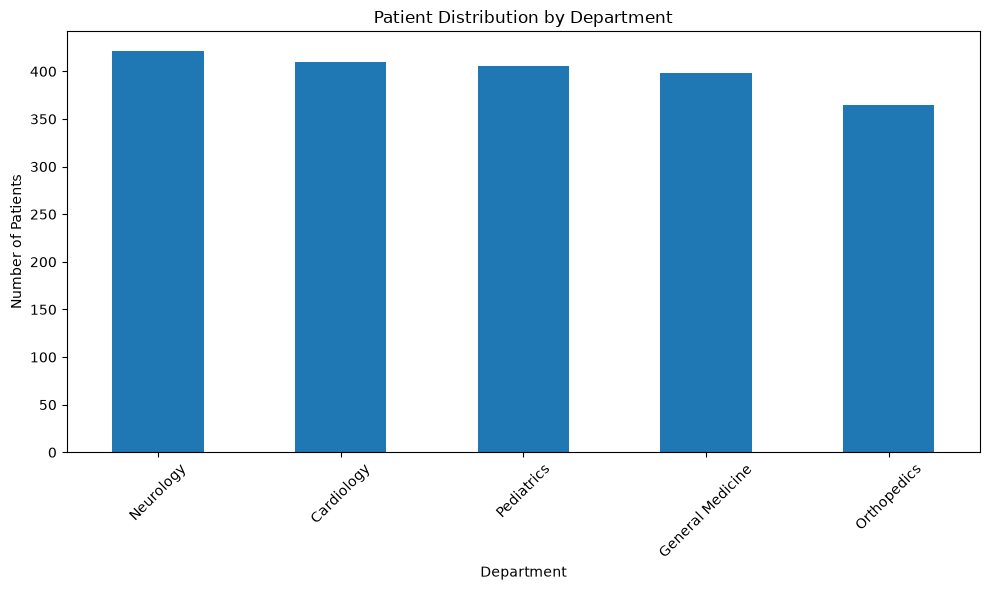

In [13]:
# Visualization 1: Patients by Department

department_counts = df["Department"].value_counts()

plt.figure(figsize=(10, 6))
department_counts.plot(kind="bar")

plt.title("Patient Distribution by Department")
plt.xlabel("Department")
plt.ylabel("Number of Patients")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_department_patients.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

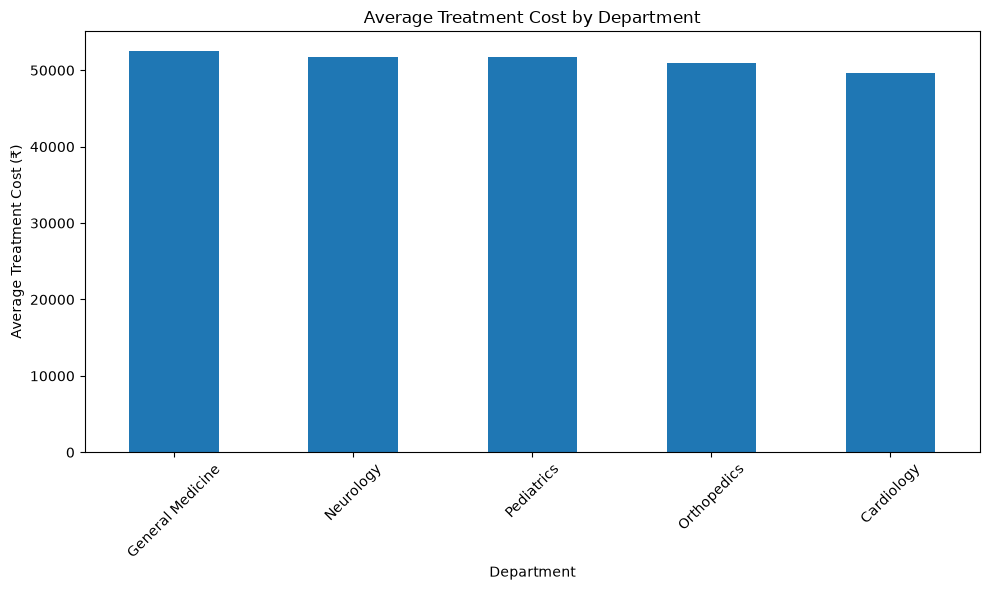

In [14]:
# Visualization 2: Average Treatment Cost by Department

avg_cost_department = (
    df.groupby("Department")["Treatment_Cost"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
avg_cost_department.plot(kind="bar")

plt.title("Average Treatment Cost by Department")
plt.xlabel("Department")
plt.ylabel("Average Treatment Cost (₹)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_department_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

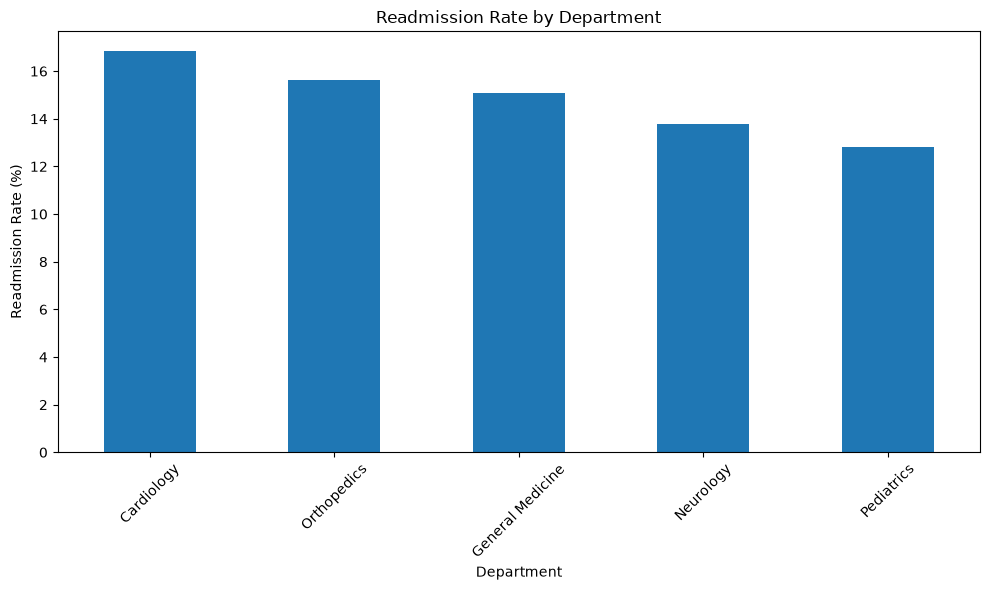

In [15]:
# Visualization 3: Readmission Rate by Department

readmission_rate = (
    df.groupby("Department")["Readmission"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
readmission_rate.plot(kind="bar")

plt.title("Readmission Rate by Department")
plt.xlabel("Department")
plt.ylabel("Readmission Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_readmission_by_department.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

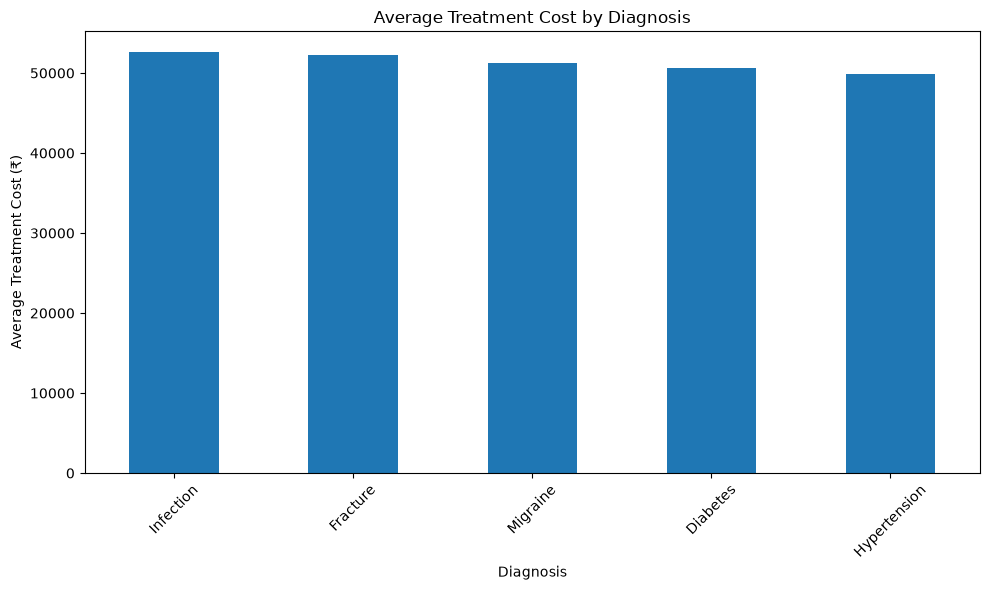

In [16]:
# Visualization 4: Average Treatment Cost by Diagnosis

avg_cost_diagnosis = (
    df.groupby("Diagnosis")["Treatment_Cost"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
avg_cost_diagnosis.plot(kind="bar")

plt.title("Average Treatment Cost by Diagnosis")
plt.xlabel("Diagnosis")
plt.ylabel("Average Treatment Cost (₹)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_diagnosis_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

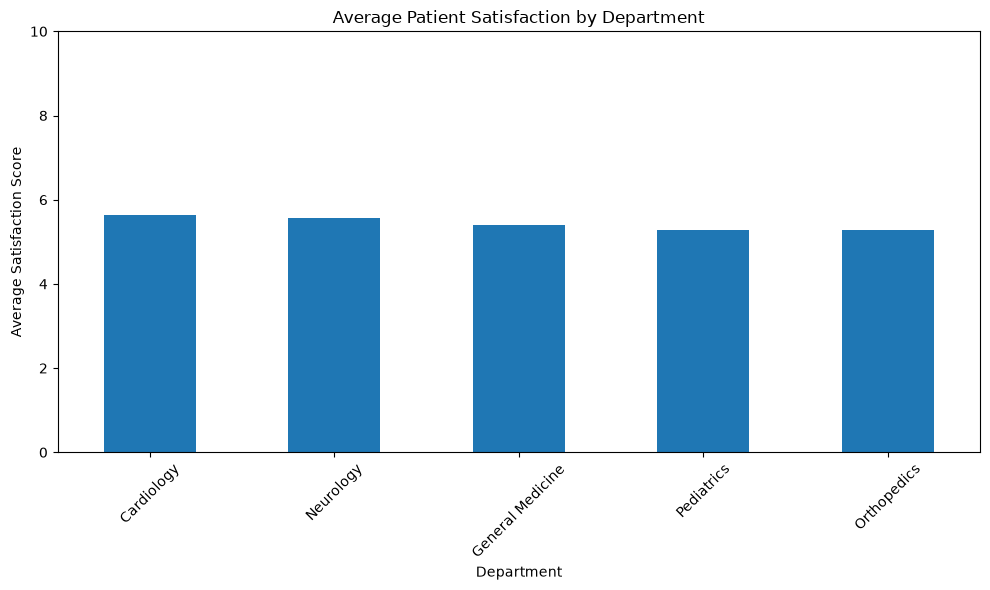

In [17]:
# Visualization 5: Patient Satisfaction by Department

avg_satisfaction_department = (
    df.groupby("Department")["Satisfaction_Score"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))
avg_satisfaction_department.plot(kind="bar")

plt.title("Average Patient Satisfaction by Department")
plt.xlabel("Department")
plt.ylabel("Average Satisfaction Score")
plt.xticks(rotation=45)
plt.ylim(0, 10)
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_satisfaction_by_department.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

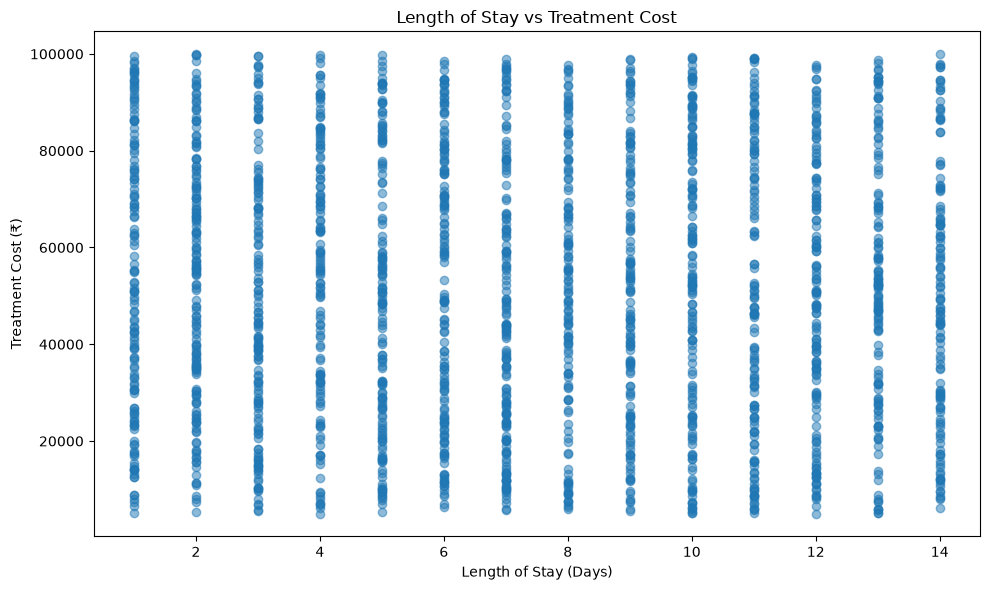

In [18]:
# Visualization 6: Length of Stay vs Treatment Cost

plt.figure(figsize=(10, 6))

plt.scatter(
    df["Length_of_Stay"],
    df["Treatment_Cost"],
    alpha=0.5
)

plt.title("Length of Stay vs Treatment Cost")
plt.xlabel("Length of Stay (Days)")
plt.ylabel("Treatment Cost (₹)")
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_stay_vs_cost.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

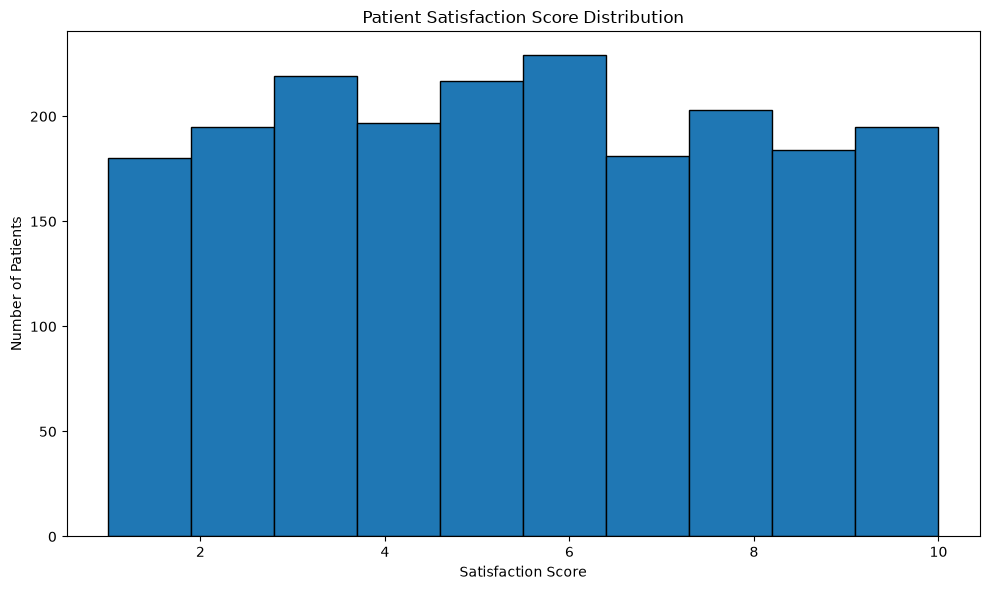

In [19]:
# Visualization 7: Patient Satisfaction Distribution

plt.figure(figsize=(10, 6))

plt.hist(
    df["Satisfaction_Score"],
    bins=10,
    edgecolor="black"
)

plt.title("Patient Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Number of Patients")
plt.tight_layout()

plt.savefig(
    r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\visualizations\healthcare_satisfaction_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [20]:
# Readmission rate by diagnosis

diagnosis_readmission = (
    df.groupby("Diagnosis")["Readmission"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .sort_values(ascending=False)
    .round(2)
)

diagnosis_readmission

Diagnosis
Hypertension    16.45
Infection       15.72
Migraine        15.25
Diabetes        14.88
Fracture        11.58
Name: Readmission, dtype: float64

In [21]:
# Final data quality validation

print("===== FINAL DATA VALIDATION =====")

print("\nDataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nUnique Patient IDs:", df["Patient_ID"].nunique())

print("\nAge Range:")
print(df["Age"].min(), "to", df["Age"].max())

print("\nLength of Stay Range:")
print(df["Length_of_Stay"].min(), "to", df["Length_of_Stay"].max())

print("\nTreatment Cost Range:")
print(df["Treatment_Cost"].min(), "to", df["Treatment_Cost"].max())

print("\nSatisfaction Score Range:")
print(df["Satisfaction_Score"].min(), "to", df["Satisfaction_Score"].max())

print("\nReadmission Values:")
print(df["Readmission"].unique())

print("\nDepartment Values:")
print(df["Department"].unique())

print("\nDiagnosis Values:")
print(df["Diagnosis"].unique())

===== FINAL DATA VALIDATION =====

Dataset Shape: (2000, 12)

Missing Values:
0

Duplicate Rows: 0

Unique Patient IDs: 2000

Age Range:
18 to 80

Length of Stay Range:
1 to 14

Treatment Cost Range:
5022.9 to 99924.69

Satisfaction Score Range:
1.0 to 10.0

Readmission Values:
<StringArray>
['No', 'Yes']
Length: 2, dtype: str

Department Values:
<StringArray>
['Orthopedics', 'Neurology', 'General Medicine', 'Pediatrics', 'Cardiology']
Length: 5, dtype: str

Diagnosis Values:
<StringArray>
['Fracture', 'Migraine', 'Hypertension', 'Infection', 'Diabetes']
Length: 5, dtype: str


In [22]:
# Save the final healthcare dataset

output_path = r"C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\healthcare_data.csv"

df.to_csv(output_path, index=False)

print("Healthcare dataset saved successfully!")
print(output_path)

Healthcare dataset saved successfully!
C:\Users\durga\OneDrive\Desktop\data-analysis-portfolio\data\healthcare_data.csv


# Executive Summary

This healthcare data analysis project examines 2,000 simulated patient records to understand hospital department performance, treatment costs, length of stay, patient satisfaction, and readmission patterns.

The analysis found an overall average patient age of 49.66 years, an average hospital stay of 7.40 days, and an average treatment cost of ₹51,319.68. The overall average patient satisfaction score was 5.43 out of 10, indicating an opportunity to improve the patient experience.

General Medicine recorded the highest average treatment cost at approximately ₹52,474, while Neurology had the largest patient volume with 421 patients. Cardiology showed the highest department-level readmission rate at 16.83%, while Pediatrics had the lowest at 12.81%.

At the diagnosis level, Hypertension had the highest readmission rate at 16.45%, while Fracture had the lowest at 11.58%. The overall readmission rate was 14.8%.

Correlation analysis showed a moderate positive relationship between treatment cost and cost per day (0.425), while length of stay and cost per day showed a stronger negative relationship (-0.614). Most other relationships were weak.

The findings suggest opportunities to improve patient satisfaction, monitor readmission patterns, optimize treatment-cost management, and focus operational attention on departments and diagnoses with higher readmission rates.

> **Note:** The dataset is simulated for analytical and portfolio demonstration purposes and should not be interpreted as real-world clinical evidence.

# Insights & Recommendations

## Key Insights

### 1. Treatment Cost
- The overall average treatment cost was **₹51,319.68**, with a median of **₹50,800.46**.
- General Medicine had the highest average treatment cost at approximately **₹52,473.54**.
- Infection had the highest average treatment cost by diagnosis at approximately **₹52,579.67**.

### 2. Hospital Stay
- The average length of stay was **7.40 days**, with a median of **7 days**.
- Hypertension patients had the longest average stay at **7.67 days**.
- Pediatrics had the highest department-level average stay at **7.50 days**.

### 3. Patient Satisfaction
- The overall average satisfaction score was **5.43/10**.
- **686 patients (34.3%)** were classified as having low satisfaction.
- Cardiology recorded the highest average department satisfaction at **5.63/10**.
- Infection and Fracture had the lowest diagnosis-level satisfaction at **5.32/10**.

### 4. Readmission
- The overall readmission rate was **14.8%**.
- Cardiology had the highest department readmission rate at **16.83%**.
- Pediatrics had the lowest department readmission rate at **12.81%**.
- Hypertension had the highest diagnosis-level readmission rate at **16.45%**.
- Fracture had the lowest diagnosis-level readmission rate at **11.58%**.

### 5. Correlation Analysis
- Treatment Cost and Cost per Day showed a moderate positive correlation of **0.425**.
- Length of Stay and Cost per Day showed a stronger negative correlation of **-0.614**.
- Satisfaction had almost no correlation with Treatment Cost (**-0.002**) or Length of Stay (**0.044**).
- These relationships describe patterns in the simulated dataset and should not be interpreted as causal relationships.

## Recommendations

### 1. Improve Patient Experience
Focus on improving patient satisfaction through better communication, reduced waiting times, clearer treatment information, and regular patient feedback.

### 2. Monitor Readmission Risk
Departments and diagnoses with higher readmission rates should receive additional post-discharge follow-up and readmission monitoring.

### 3. Review Treatment Costs
Hospital management should review high-cost departments and diagnoses to identify opportunities for efficient resource utilization while maintaining quality of care.

### 4. Optimize Length of Stay
Analyze patients with longer hospital stays to identify operational bottlenecks and opportunities to improve discharge planning.

### 5. Use Data for Continuous Monitoring
A healthcare dashboard could continuously track treatment costs, patient satisfaction, average length of stay, and readmission rates to support data-driven decision-making.

## Conclusion

The analysis demonstrates how healthcare data can be used to evaluate hospital operations, patient experience, treatment costs, and readmission patterns. The results highlight several areas where hospital management could focus improvement efforts.

Because this project uses a simulated dataset, the findings are intended for data-analysis and portfolio demonstration purposes rather than clinical decision-making.

# Healthcare Patient & Hospital Performance Analysis

## Project Overview

This project analyzes healthcare patient data to identify patterns in hospital department performance, treatment costs, length of stay, patient satisfaction, and readmission rates.

### Objectives

- Analyze patient demographics and hospital departments
- Compare treatment costs across departments and diagnoses
- Analyze hospital length of stay
- Evaluate patient satisfaction
- Measure readmission rates
- Identify relationships between healthcare metrics using correlation analysis
- Generate actionable recommendations for hospital management

### Dataset

The dataset contains **2,000 simulated patient records** with demographic, operational, financial, satisfaction, and readmission information.

**Note:** This dataset is simulated and is intended for educational and portfolio demonstration purposes.

## Data Dictionary

| Column | Description |
|---|---|
| Patient_ID | Unique identifier assigned to each patient |
| Age | Age of the patient in years |
| Gender | Patient gender |
| Department | Hospital department where the patient was treated |
| Diagnosis | Primary diagnosis recorded for the patient |
| Length_of_Stay | Number of days the patient stayed in the hospital |
| Treatment_Cost | Total estimated treatment cost in Indian Rupees |
| Satisfaction_Score | Patient satisfaction rating from 1 to 10 |
| Readmission | Indicates whether the patient was readmitted |
| Age_Group | Age category derived from patient age |
| Cost_per_Day | Treatment cost divided by length of hospital stay |
| Satisfaction_Level | Satisfaction category: Low, Medium, or High |

In [23]:
# Final Project 4 Quality Check

print("===== PROJECT 4 QUALITY CHECK =====")

print(f"Dataset rows: {len(df)}")
print(f"Dataset columns: {len(df.columns)}")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Unique patients: {df['Patient_ID'].nunique()}")

print("\nDepartments:", df["Department"].nunique())
print("Diagnoses:", df["Diagnosis"].nunique())

print("\nAverage treatment cost: ₹{:,.2f}".format(df["Treatment_Cost"].mean()))
print("Average length of stay: {:.2f} days".format(df["Length_of_Stay"].mean()))
print("Average satisfaction: {:.2f}/10".format(df["Satisfaction_Score"].mean()))

readmission_rate = (df["Readmission"] == "Yes").mean() * 100
print("Overall readmission rate: {:.2f}%".format(readmission_rate))

print("\n===== QUALITY CHECK COMPLETE =====")

===== PROJECT 4 QUALITY CHECK =====
Dataset rows: 2000
Dataset columns: 12
Missing values: 0
Duplicate rows: 0
Unique patients: 2000

Departments: 5
Diagnoses: 5

Average treatment cost: ₹51,319.68
Average length of stay: 7.40 days
Average satisfaction: 5.43/10
Overall readmission rate: 14.80%

===== QUALITY CHECK COMPLETE =====


# Project 4 — Healthcare Patient & Hospital Performance Analysis

## Project Overview

This project analyzes 2,000 simulated healthcare patient records to identify patterns in hospital department performance, treatment costs, length of stay, patient satisfaction, and readmission rates.

The analysis demonstrates practical data-analysis techniques using Python, Pandas, NumPy, and Matplotlib.

## Objectives

- Analyze patient demographics and hospital departments
- Compare treatment costs across departments and diagnoses
- Analyze hospital length of stay
- Evaluate patient satisfaction
- Calculate readmission rates
- Identify relationships between key healthcare metrics
- Perform data validation and statistical analysis
- Generate actionable recommendations

## Dataset

The dataset contains **2,000 simulated patient records**.

### Main Variables

- Patient ID
- Age
- Gender
- Department
- Diagnosis
- Length of Stay
- Treatment Cost
- Satisfaction Score
- Readmission
- Age Group
- Cost per Day
- Satisfaction Level

> **Important:** The dataset is simulated for educational and portfolio demonstration purposes. It is not intended for clinical decision-making.

## Technologies Used

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Data Quality Validation

The dataset passed the following validation checks:

- **2,000 records**
- **12 columns**
- **0 missing values**
- **0 duplicate rows**
- **2,000 unique patient IDs**
- Valid age range: 18–80
- Valid hospital stay range: 1–14 days
- Valid satisfaction range: 1–10
- Valid readmission categories
- Valid department and diagnosis categories

## Key Findings

### Treatment Cost

The average treatment cost was **₹51,319.68**, with a median of **₹50,800.46**.

General Medicine had the highest average treatment cost at approximately **₹52,473.54**.

### Length of Stay

The average hospital stay was **7.40 days**, with a median of **7 days**.

Hypertension patients had the highest diagnosis-level average stay at **7.67 days**.

### Patient Satisfaction

The overall average satisfaction score was **5.43/10**.

Low satisfaction represented **686 patients (34.3%)**, making patient experience an important improvement area.

### Readmission

The overall readmission rate was **14.8%**.

Cardiology had the highest department-level readmission rate at **16.83%**.

Hypertension had the highest diagnosis-level readmission rate at **16.45%**.

### Correlation

Treatment Cost and Cost per Day had a moderate positive correlation of **0.425**.

Length of Stay and Cost per Day had a stronger negative correlation of **-0.614**.

Most other relationships were weak.

## Visualizations

The project includes seven visualizations:

1. Patient Distribution by Department
2. Average Treatment Cost by Department
3. Readmission Rate by Department
4. Average Treatment Cost by Diagnosis
5. Patient Satisfaction by Department
6. Length of Stay vs Treatment Cost
7. Patient Satisfaction Distribution

## Business Recommendations

1. Improve patient communication and service quality to increase satisfaction.
2. Monitor departments with higher readmission rates.
3. Provide stronger post-discharge follow-up for higher-risk diagnosis groups.
4. Review high-cost departments and diagnoses for opportunities to improve resource efficiency.
5. Analyze longer hospital stays to improve discharge planning.
6. Develop a healthcare dashboard for continuous KPI monitoring.

## Project Structure

```text
data-analysis-portfolio/
├── data/
│   └── healthcare_data.csv
├── notebooks/
│   └── 04_healthcare_data_analysis.ipynb
├── reports/
│   └── healthcare_data_analysis_report.pdf
├── visualizations/
│   ├── healthcare_department_patients.png
│   ├── healthcare_department_cost.png
│   ├── healthcare_readmission_by_department.png
│   ├── healthcare_diagnosis_cost.png
│   ├── healthcare_satisfaction_by_department.png
│   ├── healthcare_stay_vs_cost.png
│   └── healthcare_satisfaction_distribution.png
└── docs/
    └── project4_healthcare_data_README.md

Conclusion

This project demonstrates a complete healthcare data-analysis workflow including data generation, cleaning, validation, statistical analysis, correlation analysis, visualization, insight generation, and business recommendations.

The workflow can be adapted to real healthcare datasets from hospitals, public-health organizations, or government open-data platforms.